# The three sensor graphs, compared

**Graph notebook 4 in `notebooks/graph/`.** It compares the graphs the three notebooks before it show, one at a time, and uses their words. Until 2026-10-02 this comparison was section 5 of notebook 02, which trained the two other graphs' networks inside the notebook for one seed; it now reads all three graphs' five-seed runs from `reports/`.

## What this notebook is for

Does the engineering knowledge in the paper's graph make the network predict better? The way to find out is to replace the graph and change nothing else. The paper does this in its "without physics prior" experiment (its Table 11), but never says what it put in place of its graph. This notebook sets the paper's graph beside two replacements — every sensor joined to every other, and the 41 most strongly correlated pairs — five seeds each, under one configuration and from one commit, on the test engines and on the held-back engines, with the seed-to-seed spread and paired tests. Then it reads the same three graphs trained with the paper's recurrent stage, which a study of one setting at a time stored at another commit (finding F-19).

## What it does not do

- **It does not train anything.** Every number comes from a stored run that names its commit.
- **It does not speak for the paper's full network.** Steps 1 to 5 read runs that give each sensor its last reading and have no recurrent stage. Step 6 reads runs with that stage, but they keep the parameters of the pass that did best on the held-back engines, which the paper never describes and which changes what the stage is worth (finding F-16). When the network changed on 2026-08-28, two of the three comparisons of settings this project then re-measured reversed direction (working rule 3), so each result here is a fact about its own configuration only.
- **It does not reproduce the paper's figure.** The paper's network without its graph costs 0.56 cycles on FD001 (its Table 11), with a replacement it never describes, in a network with a recurrent stage.
- **It does not say how the engine works.** Which graph helps this network predict is not the same question as which sensors are physically related.

## The notebook in one list

| # | Step | What goes in | What comes out |
|---|------|--------------|----------------|
| 1 | **Read the three runs' settings** | the files each run saved | the whole configuration, and a check that only the graph differs |
| 2 | **Measure what each graph does to the sensors** | seed 42's three stored networks | edges, sensors joined to nothing, edges shared with Table 3, and how many different sensors survive the first graph layer |
| 3 | **Compare the five seeds on the test engines** | each run's scores | mean and spread, and each replacement's difference from Table 3, paired by seed |
| 4 | **Compare them on the held-back engines, four ways** | each seed's error after every pass over the training data | the same comparison on the held-back error as recorded and on three summaries no pass was chosen by |
| 5 | **Find which way the errors lean** | each seed's test predictions | how often and how far each graph predicts more than the test label, the remaining life capped at 125 cycles |
| 6 | **Repeat the comparison with the recurrent stage** | the three graphs' stored runs with the paper's recurrent stage, from another commit | the same paired comparison on the test engines and the held-back engines |

## 1. Background

### Pairing by seed

A run trains five networks, seeds 42 to 46. The seed fixes three things: which 20 training engines are held back, the random numbers each network starts from, and the order the training windows arrive in. Two runs with the same seed hold back **the same 20 engines** whatever graph they train on, because which engines are held back is drawn from the seed alone. So seed 42's network on Table 3 and seed 42's network on the correlation graph are a pair: they differ in the graph and in what training made of it.

A **paired test** uses that. It takes the five differences, seed by seed, and asks whether their average is far from zero compared with how much they vary. With five made-up differences `[1, 2, 3, 2, 2]`:

```
mean of the differences          2.0
their standard deviation         0.707
standard error = 0.707 / √5      0.316
t = 2.0 / 0.316                  6.32       with 5 - 1 = 4 degrees of freedom
p                                0.0032
```

Line by line:

- **The standard deviation**, 0.707, is how far one difference typically sits from their average. The distances from 2.0 are `[-1, 0, 1, 0, 0]`; their squares add up to 2; divided by 5 - 1 = 4 that is 0.5, and its square root is 0.707.
- **The standard error**, 0.316, is how much the average of five differences would itself move if the five seeds were drawn again. An average of five moves less than one difference does, by a factor of √5, so it is 0.707 / √5.
- **t**, 6.32, counts how many standard errors the average lies from zero.
- **The degrees of freedom** say which yardstick `t` is read against. If the graph made no difference, `t` would still land somewhere near zero for each new set of seeds, scattered in a known bell-shaped pattern called Student's t-distribution. How wide that pattern is depends on how many differences went into the standard deviation, less one, because their own average was used up in measuring the distances from it: five differences give 4.
- **p**, 0.0032, is the share of that pattern lying further from zero than 6.32, on either side. `scipy.stats.ttest_rel` does all of this in one call, and for these five differences gives the same 6.32 and 0.0032.

`p` is the chance of differences at least this far from zero if the graph made no difference and only the seed did. It answers one question: could this difference be an accident of the seed? It does not answer whether the difference would hold on other engines, because the five seeds share one set of 100 test engines.

**Four measures.** The test engines are scored four ways (notebook 02's step 11 defines them). Testing four measures at the usual 0.05 gives four chances of a false alarm; dividing 0.05 among the four, a difference needs `p` below 0.0125 to clear the bar on its own (assumption A-37).

### Which engines should decide

A comparison between two configurations should be judged on the **held-back engines**, not the test engines: the test engines are kept for the final score, and a choice made by looking at them makes that score less honest. The audit of 2026-09-08 found this project had not always kept to that, which is why this notebook shows both.

The held-back error needs care of its own. After every pass over the training data a run measures its error on the held-back engines; the figure it records is the lowest of those, and that same figure chose which pass's parameters to keep (assumption A-18). The lowest of many readings sits below where the network usually was, and further below for a network whose error wanders more, so two networks can be flattered by different amounts. Each seed saved its error after every pass, so step 4 also compares three summaries that no pass was chosen by, the ones the assumptions log uses for this comparison (assumption A-27).

**Do not confuse** the held-back error with the test error. They are computed over different engines, weighted differently (every window of 20 engines against one window each of 100), and they are never comparable with each other (assumption A-06). A graph can be ahead on one and level on the other, and that is two results, not a contradiction to be explained away.

## 2. Setup

The imports, then the stored runs, chosen by the rule `notebooks/graph/README.md` gives: the newest commit at which all three graphs have a stored five-seed run of `config/fd001.yaml` that saved its trained networks, and the newest run of each graph at that commit. Every notebook in this folder chooses the same way, so all four read the same runs. If a run is missing, the cell stops and prints the commands that make them.

In [1]:
from __future__ import annotations

import logging
import sys
from dataclasses import asdict, replace
from pathlib import Path

from IPython.display import display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
import yaml

# The project's top folder is the nearest one above this notebook that holds
# pyproject.toml. Adding its src/ folder to Python's search path makes the
# package importable from a clone that was never installed.
PROJECT_ROOT = next(
    folder for folder in (Path.cwd(), *Path.cwd().parents)
    if (folder / "pyproject.toml").is_file()
)
sys.path.insert(0, str(PROJECT_ROOT / "src"))

try:
    import torch
except ImportError as missing:
    raise ImportError(
        "This notebook loads a trained network, which needs PyTorch, and PyTorch is "
        'not installed. Install the project with  pip install -e ".[model]"'
    ) from missing

from thesis_gnn_rul_xai.config import load_config
from thesis_gnn_rul_xai.graph.adjacency import build_physics_adjacency
from thesis_gnn_rul_xai.models import ModelConfig
from thesis_gnn_rul_xai.training import TrainingConfig, find_runs, load_seed
from thesis_gnn_rul_xai.utils.logging_setup import configure_logging

configure_logging(logging.ERROR)
pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 20)
plt.rcParams.update({"figure.dpi": 110, "font.size": 9})

print(f"Project root: {PROJECT_ROOT}")
print(f"PyTorch     : {torch.__version__}")

Project root: D:\Main\University\Thesis\Code\Thesis GNN RUL XAI
PyTorch     : 2.13.0+cpu


In [2]:
config = load_config(PROJECT_ROOT / "config" / "fd001.yaml")
GRAPHS = ("physics", "complete", "correlation")
SEED = 42              # the network every worked example uses
COMMAND = "python scripts/train.py --config config/fd001.yaml --graph {} --seeds 5"
# The training settings a run records in its summary.json, at their default values.
TRAINING = {key: getattr(TrainingConfig(), key) for key in (
    "epochs", "batch_size", "learning_rate", "final_learning_rate", "early_stopping_patience")}


def stored_runs(kind: str) -> list:
    # Five seeds of config/fd001.yaml with only the graph changed, the trained
    # networks saved, the network sizes of the paper's Table 4, and the default
    # training settings.
    return [
        stored for stored in find_runs(
            preprocessing=replace(config, graph=kind), seeds=5, with_weights=True,
            split="varies_with_seed", early_stopping=True, lr_schedule="step",
            temporal_stage="last_cycle",
        )
        if stored.model_config == ModelConfig()
        and {key: stored.summary.get("training", {}).get(key) for key in TRAINING} == TRAINING
    ]


found = {kind: stored_runs(kind) for kind in GRAPHS}
shared = set.intersection(*({stored.summary["commit"] for stored in runs} for runs in found.values()))
if not shared:
    missing = [kind for kind, runs in found.items() if not runs]
    raise FileNotFoundError(
        ("reports/ holds no stored five-seed run, with its networks saved, for: "
         + ", ".join(missing) if missing
         else "The stored runs of the three graphs come from different commits.")
        + "\nFrom one committed state of the code, run\n\n"
        + "\n".join("    " + COMMAND.format(kind) for kind in GRAPHS)
        + "\n\nand run this notebook again."
    )

# The newest commit at which all three graphs were stored, and the newest run
# of each graph at that commit.
newest = {
    commit: max(stored.summary["finished_utc"] for runs in found.values()
                for stored in runs if stored.summary["commit"] == commit)
    for commit in shared
}
commit = max(shared, key=newest.get)
runs = {kind: [s for s in found[kind] if s.summary["commit"] == commit][-1] for kind in GRAPHS}

# The text of this notebook quotes the runs at this commit. A newer complete set stops the
# notebook, so that the text is read again against the new output before it claims anything.
QUOTED_COMMIT = "f386291-dirty"
if commit != QUOTED_COMMIT:
    raise RuntimeError(
        f"The newest complete set of runs is at {commit}, but the text of this notebook quotes the "
        f"runs at {QUOTED_COMMIT}. Read every figure in the text again against the new output, and "
        "against assumption A-27 in docs/ASSUMPTIONS.md, then change QUOTED_COMMIT.")

print(f"Commit of all three graphs' runs: {commit}")
for kind, stored in runs.items():
    print(f"  {kind:12s} {stored.name}")

Commit of all three graphs' runs: f386291-dirty
  physics      fd001_physics_row_cap_5seed_varsplit_cfgba82e3_f386291-dirty_20260914T150004Z
  complete     fd001_complete_row_cap_5seed_varsplit_cfgf21547_f386291-dirty_20260914T150527Z
  correlation  fd001_correlation_row_cap_5seed_varsplit_cfg7fdfce_f386291-dirty_20260914T150213Z


## 3. The runs

### Step 1 — Read the three runs' settings

**What.** Every setting each run saved about itself — how the data was prepared, the network's sizes, how it was trained, and how the run was organised — laid out side by side.

**Why.** A comparison is a fact about the configuration it was measured under, and this project's comparisons have reversed when that configuration moved. The table below is the configuration, named in full.

**Check.** The three runs must differ in the graph and in nothing else, and come from one commit.

In [3]:
def saved_settings(stored) -> dict[str, str]:
    # Every setting the run saved about itself, except the prose notes and the per-seed seed.
    data = {f"data: {k}": v for k, v in stored.preprocessing.to_dict().items() if k != "notes"}
    network = {f"network: {k}": v for k, v in asdict(stored.model_config).items()}
    saved = yaml.safe_load((stored.path / f"seed_{SEED}" / "training_config.yaml").read_text(encoding="utf-8"))
    training = {f"training: {k}": v for k, v in saved.items() if k not in ("notes", "seed")}
    organised = {f"run: {k}": stored.summary.get(k)
                 for k in ("seeds", "split", "validation_fraction", "early_stopping",
                           "reported_weights", "temporal_stage", "commit")}
    return {key: str(value) for key, value in {**data, **network, **training, **organised}.items()}


settings = pd.DataFrame({kind: saved_settings(stored) for kind, stored in runs.items()})
differs = settings.index[settings.nunique(axis=1) > 1].tolist()
only_the_graph_differs = differs == ["data: graph"]
assert only_the_graph_differs, differs
display(settings)
print(f"OK  Of {len(settings)} settings, the three runs differ in one: {differs[0]}.")

,physics,complete,correlation
data: subset,FD001,FD001,FD001
data: window_size,30,30,30
data: window_stride,1,1,1
data: rul_max,125,125,125
data: clip_test_labels,True,True,True
data: normalization,zscore,zscore,zscore
data: smoothing_alpha,0.5,0.5,0.5
data: graph,physics,complete,correlation
data: adjacency_normalization,row,row,row
data: validation_fraction,0.2,0.2,0.2


OK  Of 37 settings, the three runs differ in one: data: graph.


In words, the configuration every number in steps 2 to 5 belongs to (step 6 prints how its runs differ from it): FD001; readings smoothed with weight 0.5 on the newest and rescaled on the training engines; windows of 30 cycles one cycle apart; labels capped at 125, the test labels included; each row of the graph divided by its total; 20 % of the training engines held back, a different 20 for each seed, with the parameters of the pass that did best on them kept and training stopped after 20 passes without improvement; up to 200 passes in batches of 32, with the learning rate set to drop from 0.001 to 0.0001 after pass 100, the halfway pass, though no run here got that far, so every pass used 0.001 (step 4 checks this); each sensor carrying its last reading into the graph layers, so no recurrent stage; and the layer sizes of the paper's Table 4.

### Step 2 — Measure what each graph does to the sensors

**What.** For each graph, load seed 42's stored network and count: its edges; the sensors it joins to nothing; the edges it shares with Table 3; how many different rows its rescaled table has; and how many different sensors leave the first graph layer on the first test engine's window. The three graph notebooks before this one work each of these out by hand.

**Why.** When two rows of the rescaled table are identical, those two sensors take exactly the same average of the same neighbours, and the network can no longer tell them apart. That decides how much the network can do with each graph before any result is read.

**Check.** The correlation graph must have as many edges as Table 3, and the every-sensor graph must leave one distinct sensor.

In [4]:
NAMES = {"physics": "Table 3", "complete": "every sensor joined", "correlation": "41 strongest correlations"}
table_3 = build_physics_adjacency()[0]


def different_rows(matrix) -> int:
    return len(np.unique(np.round(np.asarray(matrix, dtype=float), 9), axis=0))


structure = []
for kind in GRAPHS:
    network, data = load_seed(runs[kind], SEED)
    raw = data.adjacency_raw
    with torch.no_grad():
        carried = network.temporal(torch.from_numpy(data.test.features[:1]))
        after = torch.relu(network.graph_layers[0](carried, network.adjacency))[0].numpy()
    structure.append({
        "sensor graph": NAMES[kind],
        "edges": int(raw.sum() // 2),
        "joined to nothing": ", ".join(s for s, d in zip(data.sensor_symbols, raw.sum(axis=1)) if d == 0) or "none",
        "edges shared with Table 3": int(((raw == 1) & (table_3 == 1)).sum() // 2),
        "different rows": different_rows(data.adjacency_normalized),
        "different sensors after layer 1": different_rows(after),
    })
    del network, data
structure = pd.DataFrame(structure).set_index("sensor graph")
display(structure)

same_edge_count = bool(structure.loc[NAMES["correlation"], "edges"] == structure.loc[NAMES["physics"], "edges"])
complete_flattens = bool(structure.loc[NAMES["complete"], "different sensors after layer 1"] == 1)
assert same_edge_count and complete_flattens
print("OK  The correlation graph has Table 3's number of edges; every sensor joined leaves one distinct sensor.")

,edges,joined to nothing,edges shared with Table 3,different rows,different sensors after layer 1
sensor graph,,,,,
Table 3,41,none,41,9,9
every sensor joined,91,none,41,1,1
41 strongest correlations,41,"P15, Nc",17,10,10


OK  The correlation graph has Table 3's number of edges; every sensor joined leaves one distinct sensor.


Joining every sensor to every other leaves the network one distinct sensor: `02_complete_fd001.ipynb` shows that its prediction then depends on one number, the average of the 14 last readings. The correlation graph keeps the paper's number of edges, but shares 17 of them with it, joins two sensors to nothing, and leaves one more different row than the paper's graph does.

## 4. The results

### Step 3 — Compare the five seeds on the test engines

**What.** Each graph's five seeds on the four test measures, as mean ± standard deviation; then each replacement minus Table 3, seed by seed, with the paired test of the background.

**Why.** One seed is not a result (working rule 3), and the pairing removes the part of the seed-to-seed spread that the two graphs share.

**Check.** The three runs must have trained the same five seeds.

In [5]:
per_seed = {kind: stored.results.set_index("seed") for kind, stored in runs.items()}
seeds = runs["physics"].seeds
same_seeds = all(stored.seeds == seeds for stored in runs.values())
assert same_seeds
MEASURES = {"rmse": "test RMSE", "score": "test NASA score", "r2": "test R-squared", "asue": "test ASUE"}


def mean_and_spread(values: pd.Series) -> str:
    return f"{values.mean():.3f} ± {values.std(ddof=1):.3f}"


def paired_rows(columns: dict[str, dict[str, pd.Series]]) -> pd.DataFrame:
    # columns: label -> graph -> five values by seed. Replacement minus Table 3, paired by seed.
    rows = []
    for kind in ("complete", "correlation"):
        for label, by_graph in columns.items():
            paper, other = by_graph["physics"], by_graph[kind]
            test = stats.ttest_rel(other, paper)
            rows.append({"replacement": NAMES[kind], "measure": label,
                         "Table 3": mean_and_spread(paper), "replacement graph": mean_and_spread(other),
                         "difference": round(float((other - paper).mean()), 3),
                         "paired t": round(float(test.statistic), 2), "p": round(float(test.pvalue), 4),
                         "seeds in that direction": int((np.sign(other - paper) == np.sign((other - paper).mean())).sum())})
    return pd.DataFrame(rows).set_index(["replacement", "measure"])


print(f"Seeds {seeds}, scored on the 100 test engines; mean ± standard deviation:")
display(pd.DataFrame({NAMES[kind]: {label: mean_and_spread(per_seed[kind][m]) for m, label in MEASURES.items()}
                      for kind in GRAPHS}))

test_columns = {label: {kind: per_seed[kind][m] for kind in GRAPHS} for m, label in MEASURES.items()}
print("Replacement minus Table 3, paired by seed:")
display(paired_rows(test_columns))
for kind in ("complete", "correlation"):
    gaps = (per_seed[kind]["rmse"] - per_seed["physics"]["rmse"]).round(3).tolist()
    print(f"Test RMSE, {NAMES[kind]} minus Table 3, seeds {seeds}: {gaps}")

Seeds [42, 43, 44, 45, 46], scored on the 100 test engines; mean ± standard deviation:


,Table 3,every sensor joined,41 strongest correlations
test RMSE,16.496 ± 0.415,19.281 ± 0.432,16.592 ± 0.354
test NASA score,539.822 ± 44.748,796.082 ± 78.802,1032.722 ± 292.233
test R-squared,0.830 ± 0.008,0.768 ± 0.010,0.829 ± 0.007
test ASUE,11.651 ± 0.995,13.759 ± 0.489,9.865 ± 0.153


Replacement minus Table 3, paired by seed:


Table 3   replacement graph  difference  paired t       p  \
replacement               measure                                                                               
every sensor joined       test RMSE          16.496 ± 0.415      19.281 ± 0.432       2.784     10.51  0.0005   
                          test NASA score  539.822 ± 44.748    796.082 ± 78.802     256.261      5.46  0.0055   
                          test R-squared      0.830 ± 0.008       0.768 ± 0.010      -0.062    -10.48  0.0005   
                          test ASUE          11.651 ± 0.995      13.759 ± 0.489       2.108      5.66  0.0048   
41 strongest correlations test RMSE          16.496 ± 0.415      16.592 ± 0.354       0.096      0.48  0.6552   
                          test NASA score  539.822 ± 44.748  1032.722 ± 292.233     492.900      3.91  0.0174   
                          test R-squared      0.830 ± 0.008       0.829 ± 0.007      -0.002     -0.48  0.6570   
                          test ASUE          11.651 ± 0.995       9.865 ± 0.153      -1.786     -4.35  0.0122   

                                           seeds in that direction  
replacement               measure                                   
every sensor joined       test RMSE                              5  
                          test NASA score                        5  
                          test R-squared                         5  
                          test ASUE                              5  
41 strongest correlations test RMSE                              4  
                          test NASA score                        5  
                          test R-squared                         4  
                          test ASUE                              5

Test RMSE, every sensor joined minus Table 3, seeds [42, 43, 44, 45, 46]: [2.125, 2.822, 2.997, 3.636, 2.342]
Test RMSE, 41 strongest correlations minus Table 3, seeds [42, 43, 44, 45, 46]: [0.238, 0.311, 0.146, 0.457, -0.672]


**Every sensor joined is worse on all four measures**, by 2.784 cycles of test RMSE (*p* = 0.0005) and on every seed.

**The correlation graph cannot be told from Table 3 by RMSE or R-squared**: 0.096 cycles apart (*p* = 0.655), with seeds on both sides. Its NASA score is higher and its ASUE lower; only ASUE's difference (*p* = 0.0122) clears the bar of 0.0125 that four measures set. Step 5 finds why the two move in opposite directions.

### Step 4 — Compare them on the held-back engines, four ways

**What.** The held-back error each run recorded, and three summaries of the error after every pass, read from each seed's `training_history.csv` (assumption A-27 chose them; two were decided on before either was computed and the third added as a check):

- **The mean of the last 20 passes each run made.** A run stops once 20 passes in a row have failed to beat its best by more than 0.0001 cycles (assumption A-18). Every run here stopped that way, so these are exactly the 20 passes after the one it kept: no pass is picked out, though the stopping rule placed the window. The rule alone does not keep those 20 above the kept pass, since one could sit below it by less than 0.0001 cycles without counting as better, so the cell checks that none does. If this summary leans at all, it then leans against the network.
- **The mean of passes 1 to `n`**, where `n` is the number of passes the shortest of the fifteen runs made, so that every run has all of them. Up to the pass at which it stops, a run is the same whether or not it stops early, so within this window no pass is chosen by the held-back error. Only the window's length is: `n` is fixed by when the shortest run stopped, and it stopped by the rule that reads the held-back error.
- **The error after pass `n` alone**, one reading, as the check.

**Why.** The recorded figure is the one that chose the pass; the three summaries show whether a difference survives without that choice.

**Check.** In every run, the pass it kept must have the lowest error of all its passes, exactly, and the figure the run recorded must be that error; every run must have stopped exactly 20 passes after the one it kept; and every pass must have used the same learning rate, so that no summary straddles the drop.

In [6]:
history = {kind: {seed: pd.read_csv(stored.path / f"seed_{seed}" / "training_history.csv") for seed in seeds}
           for kind, stored in runs.items()}
shortest = min(len(h) for by_seed in history.values() for h in by_seed.values())

# The pass each run kept, numbered from 1 as results.csv numbers it, must hold the lowest
# error of all its passes, exactly, and the run must have recorded that error.
kept_is_lowest, margins = True, []
for kind in GRAPHS:
    for seed in seeds:
        error = history[kind][seed]["validation_rmse_cycles"].to_numpy()
        kept = int(per_seed[kind].loc[seed, "best_epoch"])
        kept_is_lowest &= bool(error[kept - 1] == error.min() and np.isclose(
            error[kept - 1], per_seed[kind].loc[seed, "validation_rmse"], rtol=0, atol=1e-9))
        margins.append(float(error[kept:].min() - error[kept - 1]))
stopped_20_after_kept = all(
    bool(per_seed[kind].loc[seed, "stopped_early"])
    and per_seed[kind].loc[seed, "epochs_run"] - per_seed[kind].loc[seed, "best_epoch"] == 20
    for kind in GRAPHS for seed in seeds)
rates = {float(rate) for by_seed in history.values() for h in by_seed.values() for rate in h["learning_rate"]}
one_learning_rate = len(rates) == 1
assert kept_is_lowest and stopped_20_after_kept and one_learning_rate
print("OK  In every run the kept pass has the lowest error of all its passes, and the run recorded it;")
print(f"    the closest of the 20 passes after it sits {min(margins):.4f} cycles above it.")
print(f"OK  Every run stopped 20 passes after the one it kept; every pass used learning rate {min(rates)}.")
print(f"    The shortest run made {shortest} passes, so n = {shortest}.\n")

SUMMARIES = {
    "lowest over all passes, as recorded": lambda kind: per_seed[kind]["validation_rmse"],
    "mean of the last 20 passes": lambda kind: pd.Series(
        {s: history[kind][s]["validation_rmse_cycles"].iloc[-20:].mean() for s in seeds}),
    f"mean of passes 1 to {shortest}": lambda kind: pd.Series(
        {s: history[kind][s]["validation_rmse_cycles"].iloc[:shortest].mean() for s in seeds}),
    f"pass {shortest} alone": lambda kind: pd.Series(
        {s: history[kind][s]["validation_rmse_cycles"].iloc[shortest - 1] for s in seeds}),
}
held_back = {label: {kind: summary(kind) for kind in GRAPHS} for label, summary in SUMMARIES.items()}
print("Held-back RMSE in cycles, mean ± standard deviation over the five seeds:")
display(pd.DataFrame({NAMES[kind]: {label: mean_and_spread(by_graph[kind]) for label, by_graph in held_back.items()}
                      for kind in GRAPHS}))
print("Replacement minus Table 3, paired by seed:")
held_back_paired = paired_rows(held_back)
display(held_back_paired)

# How far each run's recorded figure sits below the mean of its last 20 passes, and
# whether that amount differs between two graphs by more than the seeds disagree.
flattered = {kind: held_back["mean of the last 20 passes"][kind] - held_back["lowest over all passes, as recorded"][kind]
             for kind in GRAPHS}
print("How far the recorded figure sits below the mean of the last 20 passes, in cycles:")
for kind in GRAPHS:
    print(f"   {NAMES[kind]:26s} {flattered[kind].mean():.3f} on average; by seed {flattered[kind].round(3).tolist()}")
for kind in ("complete", "correlation"):
    test = stats.ttest_rel(flattered[kind], flattered["physics"])
    print(f"   {NAMES[kind]} minus Table 3: {(flattered[kind] - flattered['physics']).mean():+.3f}, "
          f"paired t {test.statistic:+.2f}, p {test.pvalue:.2f}")

OK  In every run the kept pass has the lowest error of all its passes, and the run recorded it;
    the closest of the 20 passes after it sits 0.0012 cycles above it.
OK  Every run stopped 20 passes after the one it kept; every pass used learning rate 0.001.
    The shortest run made 23 passes, so n = 23.

Held-back RMSE in cycles, mean ± standard deviation over the five seeds:


,Table 3,every sensor joined,41 strongest correlations
"lowest over all passes, as recorded",21.168 ± 0.870,22.615 ± 0.620,19.169 ± 1.473
mean of the last 20 passes,21.665 ± 1.068,22.837 ± 0.639,19.852 ± 1.622
mean of passes 1 to 23,21.890 ± 0.832,22.856 ± 0.621,19.910 ± 1.628
pass 23 alone,21.672 ± 1.004,22.815 ± 0.704,19.709 ± 1.568


Replacement minus Table 3, paired by seed:


Table 3 replacement graph  difference  paired t  \
replacement               measure                                                                                       
every sensor joined       lowest over all passes, as recorded  21.168 ± 0.870    22.615 ± 0.620       1.447      5.93   
                          mean of the last 20 passes           21.665 ± 1.068    22.837 ± 0.639       1.172      3.38   
                          mean of passes 1 to 23               21.890 ± 0.832    22.856 ± 0.621       0.966      3.84   
                          pass 23 alone                        21.672 ± 1.004    22.815 ± 0.704       1.143      4.05   
41 strongest correlations lowest over all passes, as recorded  21.168 ± 0.870    19.169 ± 1.473      -1.999     -4.39   
                          mean of the last 20 passes           21.665 ± 1.068    19.852 ± 1.622      -1.813     -4.54   
                          mean of passes 1 to 23               21.890 ± 0.832    19.910 ± 1.628      -1.981     -4.39   
                          pass 23 alone                        21.672 ± 1.004    19.709 ± 1.568      -1.964     -3.74   

                                                                    p  seeds in that direction  
replacement               measure                                                               
every sensor joined       lowest over all passes, as recorded  0.0041                        5  
                          mean of the last 20 passes           0.0278                        5  
                          mean of passes 1 to 23               0.0184                        5  
                          pass 23 alone                        0.0155                        5  
41 strongest correlations lowest over all passes, as recorded  0.0118                        5  
                          mean of the last 20 passes           0.0105                        5  
                          mean of passes 1 to 23               0.0118                        5  
                          pass 23 alone                        0.0202                        5

How far the recorded figure sits below the mean of the last 20 passes, in cycles:
   Table 3                    0.497 on average; by seed [0.328, 0.19, 0.932, 0.148, 0.886]
   every sensor joined        0.223 on average; by seed [0.195, 0.064, 0.253, 0.178, 0.424]
   41 strongest correlations  0.683 on average; by seed [0.279, 0.203, 1.551, 0.32, 1.062]
   every sensor joined minus Table 3: -0.274, paired t -2.13, p 0.10
   41 strongest correlations minus Table 3: +0.186, paired t +1.59, p 0.19


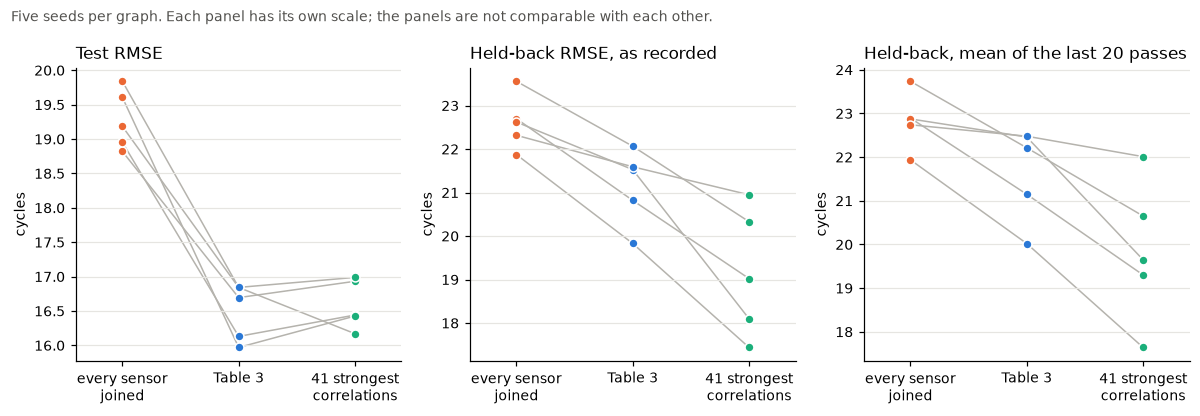

In [7]:
# Each grey line is one seed, joining its three networks; the coloured dots are the graphs.
# Table 3 sits in the middle, so each replacement's line from it is drawn directly.
ORDER = ("complete", "physics", "correlation")
COLOURS = {"physics": "#2a78d6", "complete": "#eb6834", "correlation": "#1baf7a"}
SHORT = {"physics": "Table 3", "complete": "every sensor\njoined", "correlation": "41 strongest\ncorrelations"}
panels = {
    "Test RMSE": {kind: per_seed[kind]["rmse"] for kind in GRAPHS},
    "Held-back RMSE, as recorded": held_back["lowest over all passes, as recorded"],
    "Held-back, mean of the last 20 passes": held_back["mean of the last 20 passes"],
}
figure, axes = plt.subplots(1, 3, figsize=(11, 3.8))
for axis, (title, by_graph) in zip(axes, panels.items()):
    for seed in seeds:
        axis.plot(range(3), [by_graph[kind][seed] for kind in ORDER], color="#b5b3ad", linewidth=1, zorder=1)
    for position, kind in enumerate(ORDER):
        axis.scatter([position] * len(seeds), by_graph[kind], s=34, color=COLOURS[kind],
                     edgecolor="white", linewidth=1, zorder=2)
    axis.set_xticks(range(3), [SHORT[kind] for kind in ORDER])
    axis.set_xlim(-0.4, 2.4)
    axis.set_title(title, loc="left")
    axis.set_ylabel("cycles")
    axis.grid(axis="y", color="#e6e5e1", linewidth=0.8)
    axis.spines[["top", "right"]].set_visible(False)
figure.suptitle("Five seeds per graph. Each panel has its own scale; the panels are not comparable with each other.",
                x=0.01, ha="left", fontsize=9, color="#52514e")
plt.tight_layout()
plt.show()

**On the held-back engines the correlation graph is ahead of Table 3 on every seed, in every one of the four rows**: by 1.999 cycles as recorded (*p* = 0.0118) and by 1.813 on the mean of the last 20 passes (*p* = 0.0105). The four rows summarise the same ten runs, so they are four views of one comparison rather than four experiments; taken as three separate tests anyway, at 0.05 ÷ 3 = 0.0167 the two summaries decided on in advance clear the bar, and the single reading at one pass does not.

**How much the choice of pass flattered each graph.** The recorded figure sits below the mean of the last 20 passes by 0.497 cycles on average for Table 3 and 0.683 for the correlation graph. The correlation graph is nominally flattered more, by 0.186 cycles, but five seeds cannot resolve that difference (*p* = 0.19), and either way it is under a tenth of the 1.999-cycle gap between the two graphs. The held-back advantage rests not on this difference but on the two summaries decided on in advance, which put the correlation graph lower on every seed.

**Every sensor joined is behind Table 3 on every seed in every row** here too. The choice of pass nominally flattered it least, 0.223 cycles against Table 3's 0.497, which is why its gap to Table 3 looks wider as recorded (1.447) than on the last 20 passes (1.172); five seeds cannot resolve that difference either (*p* = 0.10). At the bar of 0.0167 neither summary decided in advance clears it (*p* = 0.0278 and 0.0184), so its held-back cost is less firmly established than the recorded *p* = 0.0041 suggests, though it has the same sign on every seed.

The panels draw the same thing, with Table 3 in the middle and a grey line for each seed. On the test engines, the lines from Table 3 to the correlation graph go both up and down; on the held-back engines they all go down. The lines to every sensor joined go up in all three panels.

### Step 5 — Find which way the errors lean

**What.** For each seed, the average of the prediction minus the test label over the 100 test engines, the label being the engine's remaining life capped at 125 cycles (assumption A-02), the number every score here is computed against; how many of the 100 were predicted late, above the label, which is also more life than the engine had, since no prediction exceeds 125; and the largest late error. The cell's column `mean of predicted - label` is the first of these.

**Why.** The NASA score punishes a late prediction exponentially harder than an early one (assumption A-15), and ASUE counts only the early ones. A graph whose predictions lean late would raise the first and lower the second, which is what step 3 found for the correlation graph. This tests that reading. It was run after seeing those two results, to explain them, so it is a follow-up and not a test decided in advance.

**Check.** The averages read from each seed's `test_predictions.csv` must agree with the ones its `results.csv` recorded.

In [8]:
lean, records_agree = {}, True
for kind, stored in runs.items():
    rows = []
    for seed in seeds:
        predictions = pd.read_csv(stored.path / f"seed_{seed}" / "test_predictions.csv")
        error = predictions["predicted"] - predictions["rul"]          # positive = predicted late
        records_agree &= bool(np.isclose(error.mean(), per_seed[kind].loc[seed, "mean_error"], atol=1e-4))
        rows.append({"seed": seed, "mean of predicted - label": error.mean(),
                     "engines predicted late": int((error > 0).sum()), "largest late error": error.max()})
    lean[kind] = pd.DataFrame(rows).set_index("seed")
assert records_agree
print("OK  The predictions files agree with results.csv.\n")
print("Averaged over the five seeds:")
display(pd.DataFrame({NAMES[kind]: lean[kind].mean().round(3) for kind in GRAPHS}))
print("Replacement minus Table 3, paired by seed:")
display(paired_rows({column: {kind: lean[kind][column] for kind in GRAPHS}
                     for column in ("mean of predicted - label", "engines predicted late")}))

OK  The predictions files agree with results.csv.

Averaged over the five seeds:


,Table 3,every sensor joined,41 strongest correlations
mean of predicted - label,0.860,2.871,2.611
engines predicted late,50.800,56.400,55.200
largest late error,45.708,45.966,59.313


Replacement minus Table 3, paired by seed:


Table 3 replacement graph  difference  paired t       p  \
replacement               measure                                                                                     
every sensor joined       mean of predicted - label   0.860 ± 1.551     2.871 ± 1.615       2.010      2.97  0.0413   
                          engines predicted late     50.800 ± 6.496    56.400 ± 3.647       5.600      2.31  0.0817   
41 strongest correlations mean of predicted - label   0.860 ± 1.551     2.611 ± 1.320       1.751      8.80  0.0009   
                          engines predicted late     50.800 ± 6.496    55.200 ± 5.933       4.400      4.74  0.0090   

                                                     seeds in that direction  
replacement               measure                                             
every sensor joined       mean of predicted - label                        5  
                          engines predicted late                           5  
41 strongest correlations mean of predicted - label                        5  
                          engines predicted late                           5

**The correlation graph's predictions lean late against the label, on every seed**: on average 2.611 cycles above it, against 0.860 for Table 3 (*p* = 0.0009), with more engines predicted late and a larger worst case. That is why its NASA score is higher and its ASUE lower at almost the same RMSE: errors of about the same size, shifted 1.751 cycles further late on average, since Table 3's average lies above the label too, though its spread from seed to seed, 1.551, is larger than that average. Every sensor joined leans late too, by a similar amount on average, but less steadily from seed to seed.

(Corrected 2026-10-03: this step called the label the actual remaining life, its averages "more than the engine had", and the cell's first column `mean of predicted - actual`. The label is capped at 125, and 11 of the 100 test engines have more than 125 cycles left, 107 cycles above the cap between them, so against the uncapped remaining life every seed's average is 1.070 cycles lower: −0.210 ± 1.551 for Table 3, which then has no consistent lean (three seeds late, two early), 1.541 ± 1.320 for the correlation graph, below zero on seed 46 at −0.415, and 1.801 ± 1.615 for every sensor joined. Measured on 2026-10-03 from the same stored predictions, with the code at commit `6733d77`; no cell of this notebook prints them, and `tests/test_examples.py::test_example_the_lean_of_the_errors_against_the_capped_label_and_against_the_life_truly_left` recomputes them. The differences between graphs, the counts of late engines and the largest late errors are the same either way, because no prediction exceeds 125. Found by a review of the wording around the capped label.)

### Step 6 — Repeat the comparison with the recurrent stage

**What.** The same three graphs trained with the paper's recurrent stage — one small recurrent network per sensor, which reads that sensor's 30 cycles in order and hands one number to the graph layers (notebook 02's step 9) — five seeds each, and the comparisons of steps 3 and 4 on them. The only stored set of all three is inside a study that changed one setting at a time around the paper's network (finding F-19); the cell searches `reports/` as well, so a set trained there later is found too.

**Why.** Steps 1 to 5 describe a network without that stage, and this project's comparisons have reversed when the network changed (working rule 3).

**Check.** The three runs must differ in the graph alone, and every way they differ from the runs of steps 1 to 5 is printed. The checks of step 4 must hold for these fifteen runs too.

In [9]:
# The same three graphs with the recurrent stage. Runs written straight into reports/ are
# searched as well as the folders of the study of one setting at a time.
STUDIES = sorted((PROJECT_ROOT / "reports").glob("sensitivity_*/runs/FD001"))
RECURRENT = replace(ModelConfig(), temporal="lstm")


def stored_recurrent_runs(kind: str) -> list:
    # As stored_runs in the setup cell, with the recurrent stage in place of the last reading.
    return sorted((
        stored for root in [PROJECT_ROOT / "reports", *STUDIES] for stored in find_runs(
            root=root, preprocessing=replace(config, graph=kind), seeds=5, with_weights=True,
            split="varies_with_seed", early_stopping=True, lr_schedule="step", temporal_stage="lstm",
        )
        if stored.model_config == RECURRENT
        and {key: stored.summary.get("training", {}).get(key) for key in TRAINING} == TRAINING
    ), key=lambda stored: stored.summary["finished_utc"])


found_lstm = {kind: stored_recurrent_runs(kind) for kind in GRAPHS}
shared_lstm = set.intersection(*({s.summary["commit"] for s in by_kind} for by_kind in found_lstm.values()))
if not shared_lstm:
    raise FileNotFoundError(
        "No commit holds a stored five-seed run of all three graphs with the recurrent stage."
        "\nFrom one committed state of the code, run\n\n"
        + "\n".join("    " + COMMAND.format(kind) + " --temporal lstm" for kind in GRAPHS)
        + "\n\nand run this notebook again.")
commit_lstm = max(shared_lstm, key=lambda c: max(
    s.summary["finished_utc"] for by_kind in found_lstm.values() for s in by_kind if s.summary["commit"] == c))
runs_lstm = {kind: [s for s in found_lstm[kind] if s.summary["commit"] == commit_lstm][-1] for kind in GRAPHS}

# As in the setup cell: the text below quotes these runs, so a newer complete set stops the notebook.
QUOTED_COMMIT_LSTM = "fd65a3b-dirty"
if commit_lstm != QUOTED_COMMIT_LSTM:
    raise RuntimeError(
        f"The newest complete set of recurrent-stage runs is at {commit_lstm}, but the text of this "
        f"notebook quotes the runs at {QUOTED_COMMIT_LSTM}. Read the text of step 6 and section 5 again "
        "against the new output, then change QUOTED_COMMIT_LSTM.")

print(f"Commit of all three graphs' recurrent-stage runs: {commit_lstm}")
for kind, stored in runs_lstm.items():
    print(f"  {kind:12s} {stored.path.relative_to(PROJECT_ROOT / 'reports')}")
    print(f"  {'':12s} uncommitted changes it recorded: {stored.summary.get('uncommitted_code')}")
RECORDED = ["seed", "rmse", "validation_rmse", "best_epoch"]
for kind, by_kind in found_lstm.items():
    for stored in by_kind:
        if stored is not runs_lstm[kind]:
            identical = stored.results[RECORDED].equals(runs_lstm[kind].results[RECORDED])
            print(f"  also stored, not used: {NAMES[kind]} at {stored.summary['commit']}, "
                  f"test RMSE {mean_and_spread(stored.results['rmse'])}"
                  + ("; identical to the run used, seed by seed" if identical else ""))

# Among themselves the three must differ in the graph alone.
settings_lstm = pd.DataFrame({kind: saved_settings(stored) for kind, stored in runs_lstm.items()})
only_the_graph_differs_lstm = settings_lstm.index[settings_lstm.nunique(axis=1) > 1].tolist() == ["data: graph"]
assert only_the_graph_differs_lstm
print(f"\nOK  Of {len(settings_lstm)} settings, the three runs differ in one: data: graph.")
print("    From the runs of steps 1 to 5 they also differ in:")
for key in settings_lstm.index[settings_lstm["physics"] != settings["physics"]]:
    print(f"      {key:24s} {settings.loc[key, 'physics']} -> {settings_lstm.loc[key, 'physics']}")

# The checks of step 4, on these fifteen runs.
per_seed_lstm = {kind: stored.results.set_index("seed") for kind, stored in runs_lstm.items()}
history_lstm = {kind: {seed: pd.read_csv(stored.path / f"seed_{seed}" / "training_history.csv")
                       for seed in seeds} for kind, stored in runs_lstm.items()}
error_lstm = {kind: {seed: h["validation_rmse_cycles"].to_numpy() for seed, h in by_seed.items()}
              for kind, by_seed in history_lstm.items()}
kept_lstm = {(kind, seed): int(per_seed_lstm[kind].loc[seed, "best_epoch"]) for kind in GRAPHS for seed in seeds}
checks_hold_lstm = all(stored.seeds == seeds for stored in runs_lstm.values()) and all(
    error[kept_lstm[kind, seed] - 1] == error.min()
    and np.isclose(error.min(), per_seed_lstm[kind].loc[seed, "validation_rmse"], rtol=0, atol=1e-9)
    and len(error) - kept_lstm[kind, seed] == 20
    and error[kept_lstm[kind, seed]:].min() > error.min()
    for kind in GRAPHS for seed, error in error_lstm[kind].items()
) and {float(r) for by_seed in history_lstm.values() for h in by_seed.values() for r in h["learning_rate"]} == {0.001}
assert checks_hold_lstm
shortest_lstm = min(len(error) for by_seed in error_lstm.values() for error in by_seed.values())
print("OK  Same seeds. In every run the kept pass has the lowest held-back error and none of the 20")
print("    passes after it is lower; every run stopped 20 passes after it; every pass used learning")
print(f"    rate 0.001. The shortest run made {shortest_lstm} passes, so here n = {shortest_lstm}.\n")

print("Test engines, recurrent stage. Replacement minus Table 3, paired by seed:")
display(paired_rows({label: {kind: per_seed_lstm[kind][m] for kind in GRAPHS} for m, label in MEASURES.items()}))
SUMMARIES_LSTM = {
    "lowest over all passes, as recorded": lambda kind: per_seed_lstm[kind]["validation_rmse"],
    "mean of the last 20 passes": lambda kind: pd.Series({s: e[-20:].mean() for s, e in error_lstm[kind].items()}),
    f"mean of passes 1 to {shortest_lstm}": lambda kind: pd.Series(
        {s: e[:shortest_lstm].mean() for s, e in error_lstm[kind].items()}),
    f"pass {shortest_lstm} alone": lambda kind: pd.Series({s: e[shortest_lstm - 1] for s, e in error_lstm[kind].items()}),
}
held_back_lstm = {label: {kind: summary(kind) for kind in GRAPHS} for label, summary in SUMMARIES_LSTM.items()}
print("Held-back engines, recurrent stage. Replacement minus Table 3, paired by seed:")
display(paired_rows(held_back_lstm))

Commit of all three graphs' recurrent-stage runs: fd65a3b-dirty
  physics      sensitivity_fd65a3b-dirty_20260929T101059Z\runs\FD001\reference
               uncommitted changes it recorded: ['?? scripts/run_sensitivity.py']
  complete     sensitivity_fd65a3b-dirty_20260929T101059Z\runs\FD001\graph_complete
               uncommitted changes it recorded: [' M src/thesis_gnn_rul_xai/docsite/README.md', ' M src/thesis_gnn_rul_xai/docsite/assets/playground.js', ' M src/thesis_gnn_rul_xai/docsite/playground.py', '?? scripts/run_sensitivity.py']
  correlation  sensitivity_fd65a3b-dirty_20260929T101059Z\runs\FD001\graph_correlation
               uncommitted changes it recorded: [' M src/thesis_gnn_rul_xai/docsite/README.md', ' M src/thesis_gnn_rul_xai/docsite/assets/playground.js', ' M src/thesis_gnn_rul_xai/docsite/playground.py', '?? scripts/run_sensitivity.py']
  also stored, not used: Table 3 at f386291-dirty, test RMSE 13.307 ± 0.532
  also stored, not used: Table 3 at 19dceb5, test RM

Table 3 replacement graph  difference  paired t       p  \
replacement               measure                                                                             
every sensor joined       test RMSE          13.234 ± 0.723    13.636 ± 0.601       0.402      1.00  0.3723   
                          test NASA score  316.314 ± 57.200  330.824 ± 44.673      14.510      0.65  0.5519   
                          test R-squared      0.891 ± 0.012     0.884 ± 0.010      -0.007     -1.02  0.3662   
                          test ASUE           8.146 ± 0.478     9.521 ± 1.497       1.375      2.53  0.0647   
41 strongest correlations test RMSE          13.234 ± 0.723    13.237 ± 0.967       0.002      0.01  0.9947   
                          test NASA score  316.314 ± 57.200  308.785 ± 58.284      -7.529     -0.22  0.8372   
                          test R-squared      0.891 ± 0.012     0.890 ± 0.016      -0.000     -0.05  0.9652   
                          test ASUE           8.146 ± 0.478     9.025 ± 0.942       0.879      1.53  0.2005   

                                           seeds in that direction  
replacement               measure                                   
every sensor joined       test RMSE                              4  
                          test NASA score                        2  
                          test R-squared                         4  
                          test ASUE                              5  
41 strongest correlations test RMSE                              1  
                          test NASA score                        4  
                          test R-squared                         1  
                          test ASUE                              4

Held-back engines, recurrent stage. Replacement minus Table 3, paired by seed:


Table 3 replacement graph  difference  paired t  \
replacement               measure                                                                                       
every sensor joined       lowest over all passes, as recorded  14.184 ± 0.389    14.296 ± 0.548       0.112      1.45   
                          mean of the last 20 passes           15.463 ± 0.738    15.447 ± 0.784      -0.016     -0.12   
                          mean of passes 1 to 25               15.322 ± 0.757    15.443 ± 0.691       0.122      0.93   
                          pass 25 alone                        15.220 ± 0.559    15.401 ± 0.495       0.181      1.34   
41 strongest correlations lowest over all passes, as recorded  14.184 ± 0.389    13.494 ± 0.362      -0.690     -6.64   
                          mean of the last 20 passes           15.463 ± 0.738    14.846 ± 0.525      -0.617     -2.02   
                          mean of passes 1 to 25               15.322 ± 0.757    14.853 ± 0.548      -0.469     -3.08   
                          pass 25 alone                        15.220 ± 0.559    14.741 ± 0.467      -0.479     -1.58   

                                                                    p  seeds in that direction  
replacement               measure                                                               
every sensor joined       lowest over all passes, as recorded  0.2208                        4  
                          mean of the last 20 passes           0.9124                        3  
                          mean of passes 1 to 25               0.4038                        3  
                          pass 25 alone                        0.2511                        3  
41 strongest correlations lowest over all passes, as recorded  0.0027                        5  
                          mean of the last 20 passes           0.1134                        4  
                          mean of passes 1 to 25               0.0368                        5  
                          pass 25 alone                        0.1883                        4

**With the recurrent stage, neither replacement can be told from Table 3 on the test engines.** Every sensor joined costs 0.402 cycles of test RMSE (*p* = 0.372), where without the stage it cost 2.784; the 41 strongest correlations differ from Table 3 by 0.002 (*p* = 0.995); and no test measure of either clears the bar of 0.0125 that four measures set. The correlation graph's NASA score is no longer higher than Table 3's (*p* = 0.837).

**On the held-back engines the correlation graph is lower than Table 3 again, but less firmly.** As recorded it is 0.690 cycles lower, on every seed (*p* = 0.0027). On the two summaries decided on in advance the gap is smaller and less steady: 0.617 cycles on the mean of the last 20 passes (*p* = 0.113, four seeds of five) and 0.469 on the mean of passes 1 to 25 (*p* = 0.037). Neither clears the bar of 0.0167 that step 4 set, so with the stage the advantage rests mainly on the figure the choice of pass flattered. Every sensor joined cannot be told from Table 3 on any of the four held-back rows.

Three cautions go with these runs:

- **They are at another commit and with another device setting** than the runs of steps 1 to 5, as the cell prints, so only their paired differences are set beside those of steps 1 to 5, never their raw figures. Even Table 3 with the recurrent stage gives 13.307 ± 0.532 in the run stored at `f386291-dirty`, not this run's 13.234 ± 0.723. Table 3 and the correlation graph were trained again with the stage on 2026-10-02 at the committed state `19dceb5`, and the cell finds both identical, seed by seed, to the runs used here; the every-sensor graph had no run at that commit when this was written, so the set at `fd65a3b-dirty` is the newest with all three.
- **They keep the parameters of the pass that did best on the held-back engines**, which the paper never describes. For the recurrent stage that one choice moves what the stage is worth from 0.77 cycles to 3.19 (finding F-16); what it does to this comparison has not been measured.
- **Their commit is marked as having uncommitted changes**, and the runs recorded which: the cell prints them, and they touch the documentation site and the study's own script, not the code that trains the network.

## 5. What the comparison says

Every number in this section is printed by a cell above. Steps 1 to 5 belong to the configuration of step 1: one number per sensor, no recurrent stage, 20 % of engines held back, at commit `f386291-dirty`, and `docs/ASSUMPTIONS.md` records the same figures from the same runs (assumption A-27 and finding F-04). Step 6 belongs to the same configuration with the recurrent stage, at commit `fd65a3b-dirty`, from the runs of the study of one setting at a time (finding F-19).

- **Joining every sensor to every other costs a great deal without the recurrent stage, and nothing five seeds can tell from zero with it.** Without the stage it is worse than Table 3 on every measure and every seed, by 2.784 cycles of test RMSE. `02_complete_fd001.ipynb` shows what the graph does in that network: it averages the 14 sensors' last readings into one number before anything is learned. The correlation graph removes the same engineering knowledge but keeps 41 edges, and costs 0.096, so most of the 2.784 is probably that averaging rather than the loss of the paper's knowledge of which sensors are related. That is an inference from two measurements, not a measurement of its own. With the stage each sensor's number is learned before it is averaged, and the cost falls to 0.402 cycles (*p* = 0.372); whether that learning is the reason has not been measured.
- **Without the recurrent stage, the data's own 41 strongest relationships do as well as the paper's 41 on the test engines by RMSE and R-squared, and better on the held-back engines.** Test RMSE differs by 0.096 cycles (*p* = 0.655). The NASA score favours Table 3 on all five seeds (*p* = 0.0174, short of the bar of 0.0125), and ASUE favours the correlation graph (*p* = 0.0122, which clears it). On the held-back engines the correlation graph is ahead on every seed, by about 1.8 to 2.0 cycles however that error is summarised, and the choice of pass does not account for it. The held-back and test errors are not comparable with each other (assumption A-06), and nothing here explains why one shows a difference and the other does not.
- **Without the stage it makes different mistakes.** Its test predictions lean further late than Table 3's, which the NASA score punishes and ASUE ignores.
- **With the recurrent stage, the two graphs cannot be told apart on the test engines by any of the four measures**, and the correlation graph's held-back advantage shrinks to 0.5 to 0.7 cycles, firm only on the figure the choice of pass flattered.

So in both configurations measured here, the paper's engineering knowledge, set against the same number of edges chosen from the data, does not make the network more accurate on the test engines by RMSE or R-squared, and on the held-back engines it is the data's graph that is ahead. Without the stage, Table 3's test errors were late less often and less severely, which gave it the better NASA score; with the stage that difference is not there. The paper's Conclusions claim its graph captures relationships "beyond data-driven correlations" (item 2); these runs find no advantage in accuracy for the paper's graph over one built from correlations except that NASA score, without the stage. Neither configuration follows the paper's own procedure, which holds nothing back and keeps the parameters after the last of 200 passes. For the recurrent stage that procedure changes what the stage is worth (finding F-16); what it would do to these comparisons has not been measured.

The paper's own figure for removing its graph is 0.56 cycles on FD001 (its Table 11), for its full network, with a replacement it never describes. Nothing here reproduces it, and the history of the every-sensor comparison in `docs/ASSUMPTIONS.md` shows that figure moving with the preprocessing (finding F-04).

## 6. Final verification

Every check in this notebook, in one place.

In [10]:
# Figures the text quotes, beside the same figures computed above; each must round to its quote.
def gap(by_graph: dict, kind: str) -> float:
    return float((by_graph[kind] - by_graph["physics"]).mean())


test_lstm = {label: {kind: per_seed_lstm[kind][m] for kind in GRAPHS} for m, label in MEASURES.items()}
quoted = {
    "test RMSE, every sensor joined": (2.784, gap(test_columns["test RMSE"], "complete")),
    "test RMSE, correlations": (0.096, gap(test_columns["test RMSE"], "correlation")),
    "held-back as recorded, correlations": (-1.999, gap(held_back["lowest over all passes, as recorded"], "correlation")),
    "held-back last 20, correlations": (-1.813, gap(held_back["mean of the last 20 passes"], "correlation")),
    "lean, correlations": (1.751, gap({k: lean[k]["mean of predicted - label"] for k in GRAPHS}, "correlation")),
    "stage, test RMSE, every sensor joined": (0.402, gap(test_lstm["test RMSE"], "complete")),
    "stage, test RMSE, correlations": (0.002, gap(test_lstm["test RMSE"], "correlation")),
    "stage, held-back as recorded, correlations": (-0.690, gap(held_back_lstm["lowest over all passes, as recorded"], "correlation")),
    "stage, held-back last 20, correlations": (-0.617, gap(held_back_lstm["mean of the last 20 passes"], "correlation")),
    "stage, held-back passes 1 to n, correlations": (-0.469, gap(held_back_lstm[f"mean of passes 1 to {shortest_lstm}"], "correlation")),
}
text_matches = all(round(value, 3) == text for text, value in quoted.values())
assert text_matches, {name: (text, round(value, 3)) for name, (text, value) in quoted.items()}

checks = [
    ("The three runs differ only in the graph", only_the_graph_differs, f"{len(settings)} settings"),
    ("The three runs come from one commit", len({s.summary["commit"] for s in runs.values()}) == 1, commit),
    ("Correlation graph has Table 3's number of edges", same_edge_count,
     f"{structure.loc[NAMES['correlation'], 'edges']} edges"),
    ("Every sensor joined leaves one distinct sensor", complete_flattens, "after layer 1"),
    ("The three runs trained the same seeds", same_seeds, f"{seeds}"),
    ("The kept pass has each history's lowest error", kept_is_lowest,
     f"closest later pass +{min(margins):.4f} cycles"),
    ("Every run stopped 20 passes after the one kept", stopped_20_after_kept, "15 runs"),
    ("Every pass used one learning rate", one_learning_rate,
     f"{shortest} to {max(len(h) for by_seed in history.values() for h in by_seed.values())} passes"),
    ("Predictions files agree with results.csv", records_agree, "mean of predicted - label"),
    ("Recurrent-stage runs differ only in the graph", only_the_graph_differs_lstm, commit_lstm),
    ("Step 4's checks hold for the recurrent-stage runs", checks_hold_lstm, f"n = {shortest_lstm}"),
    ("The text quotes the figures printed above", text_matches, f"{len(quoted)} figures"),
]

width = max(len(name) for name, _, _ in checks) + 2
print(f"{'CHECK':<{width}} RESULT   DETAIL")
print("-" * (width + 40))
for name, passed, detail in checks:
    print(f"{name:<{width}} {'PASS' if passed else 'FAIL':<8} {detail}")
print("-" * (width + 40))
failed = [name for name, passed, _ in checks if not passed]
if failed:
    raise AssertionError(f"{len(failed)} check(s) failed: {failed}")
print(f"All {len(checks)} checks passed.")

CHECK                                               RESULT   DETAIL
-------------------------------------------------------------------------------------------
The three runs differ only in the graph             PASS     37 settings
The three runs come from one commit                 PASS     f386291-dirty
Correlation graph has Table 3's number of edges     PASS     41 edges
Every sensor joined leaves one distinct sensor      PASS     after layer 1
The three runs trained the same seeds               PASS     [42, 43, 44, 45, 46]
The kept pass has each history's lowest error       PASS     closest later pass +0.0012 cycles
Every run stopped 20 passes after the one kept      PASS     15 runs
Every pass used one learning rate                   PASS     23 to 75 passes
Predictions files agree with results.csv            PASS     mean of predicted - label
Recurrent-stage runs differ only in the graph       PASS     fd65a3b-dirty
Step 4's checks hold for the recurrent-stage runs   PASS     n

## 7. Summary

### What this notebook produced

- **The three stored runs' configuration, named in full**, checked to differ in the graph alone and to come from one commit.
- **What each graph does to the sensors**, read off seed 42's three stored networks.
- **The five-seed comparison** on the test engines, on the held-back engines as recorded and on three summaries no pass was chosen by, and on which way each graph's errors lean, each replacement paired by seed against Table 3.
- **The same comparison with the recurrent stage**, from the three stored runs of the study of one setting at a time, at another commit, on the test engines and on the same four held-back summaries.

### Decisions that were not read from the paper

| Decision | Value used | Written up as |
|---|---|---|
| What replaces the paper's graph in "without physics prior" | Every sensor joined to every other | A-19 |
| A graph built from the data | The 41 most strongly correlated pairs on the training engines | A-27 |
| The summaries of the held-back error no pass was chosen by | The mean of the last 20 passes, the mean of the first passes every run made, and the last of those alone | A-27 |
| How the table is rescaled | Each row of `A + I` divided by its own total | A-21 |
| What a sensor carries into the graph layers, steps 1 to 5 | The last reading of its window, one number | A-07 |
| Size of the recurrent stage, step 6 | One network per sensor, one layer of hidden size 32, projected to one number | A-26 |
| Held-back engines and the parameters kept | 20 % of the training engines; the parameters of the pass that did best on them | A-06 |
| When training stops | After 20 passes without improvement on the held-back engines | A-18 |
| The bar for several tests at once | 0.05 divided by the number of tests: four measures, or three held-back summaries | A-37 |

### What comes next

The comparison with the recurrent stage is stored, but at another commit and with another device setting from the runs without it, so the two halves of this notebook differ in more than the stage. Two measurements remain open:

1. **Both halves from one committed state of the code**, so that the stage is the only difference between steps 1 to 5 and step 6. Step 6 searches `reports/` too, so a set made by these commands is found; change its `QUOTED_COMMIT_LSTM`, and its text, when it is:

```bash
python scripts/train.py --config config/fd001.yaml --graph physics --temporal lstm --seeds 5
python scripts/train.py --config config/fd001.yaml --graph complete --temporal lstm --seeds 5
python scripts/train.py --config config/fd001.yaml --graph correlation --temporal lstm --seeds 5
```

2. **The paper's own procedure**, holding no engines back and keeping the parameters after the last of 200 passes. For the recurrent stage that procedure changes what the stage is worth (finding F-16), and no comparison of graphs has been run under it.

(Corrected 2026-10-02, before this notebook was first committed. A review the same day found that it asked for the recurrent-stage comparison as though no run of it were stored, when the study of one setting at a time had stored all three graphs with that stage, and step 6 now reads them; that it said the correlation graph did as well as Table 3 on the test engines without saying this holds for RMSE and R-squared but not for the NASA score; that it said the correlation graph's errors lean "the other way" when Table 3's lean late too; that it said nothing in the mean of passes 1 to `n` depends on the held-back error, when `n` was set by a run that error stopped; and that its paired test used a standard error, degrees of freedom and `p` without saying what they are.)

### References

- Wen, J.-R., et al. (2026). Explainable spatiotemporal graph neutral network with dynamic SHAP enhancement for aeroengine RUL prediction. *Aerospace Science and Technology*, 168, 110875.

Full citations are in `docs/REFERENCES.md`.